In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp

x = np.array([
    -1.77, 2.47, 1.34, 2.18, 13.05,
    1.60, 1.50, -1.97, 0.79, 1.50,
    2.00, 2.63, 1.19, -2.31, 0.87
])

n = len(x)
rng = np.random.default_rng(42)

def log_g(alpha, b):
    return n*b - np.sum(
        np.logaddexp(2*b, 2*np.log(np.maximum(
            np.abs(x-alpha), 1e-300
        )))
    )

def metropolis(s, T=50_000):
    chain = np.zeros((T+1, 2))
    accepted = 0

    current_logp = log_g(0, 0)

    for t in range(T):
        proposal = chain[t] + s*rng.normal(size=2)
        proposal_logp = log_g(*proposal)

        log_ratio = proposal_logp - current_logp

        if np.log(rng.random()) < min(0, log_ratio):
            chain[t+1] = proposal
            current_logp = proposal_logp
            accepted += 1
        else:
            chain[t+1] = chain[t]

    return chain, accepted/T

def integrated_autocorr(series):
    series = np.asarray(series, dtype=float)
    y = series - series.mean()
    N = len(y)

    size = 1 << (2*N-1).bit_length()
    f = np.fft.rfft(y, n=size)
    acf = np.fft.irfft(f*np.conj(f), n=size)[:N]
    acf /= np.arange(N, 0, -1)

    if acf[0] <= 0:
        return np.nan

    acf /= acf[0]

    tau = 1.0
    for k in range(1, N-1, 2):
        pair = acf[k] + acf[k+1]
        if pair <= 0:
            break
        tau += 2*pair

    return tau

step_sizes = [0.02, 0.5, 5]
chains = {}
results = []

for s in step_sizes:
    chain, rate = metropolis(s)
    chains[s] = chain

    tau = integrated_autocorr(chain[5001:, 0])

    results.append({
        "s": s,
        "Acceptance rate": rate,
        "IAT alpha": tau
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


   s  Acceptance rate  IAT alpha
0.02          0.96444 567.762706
0.50          0.37168   8.021191
5.00          0.00874 235.015405


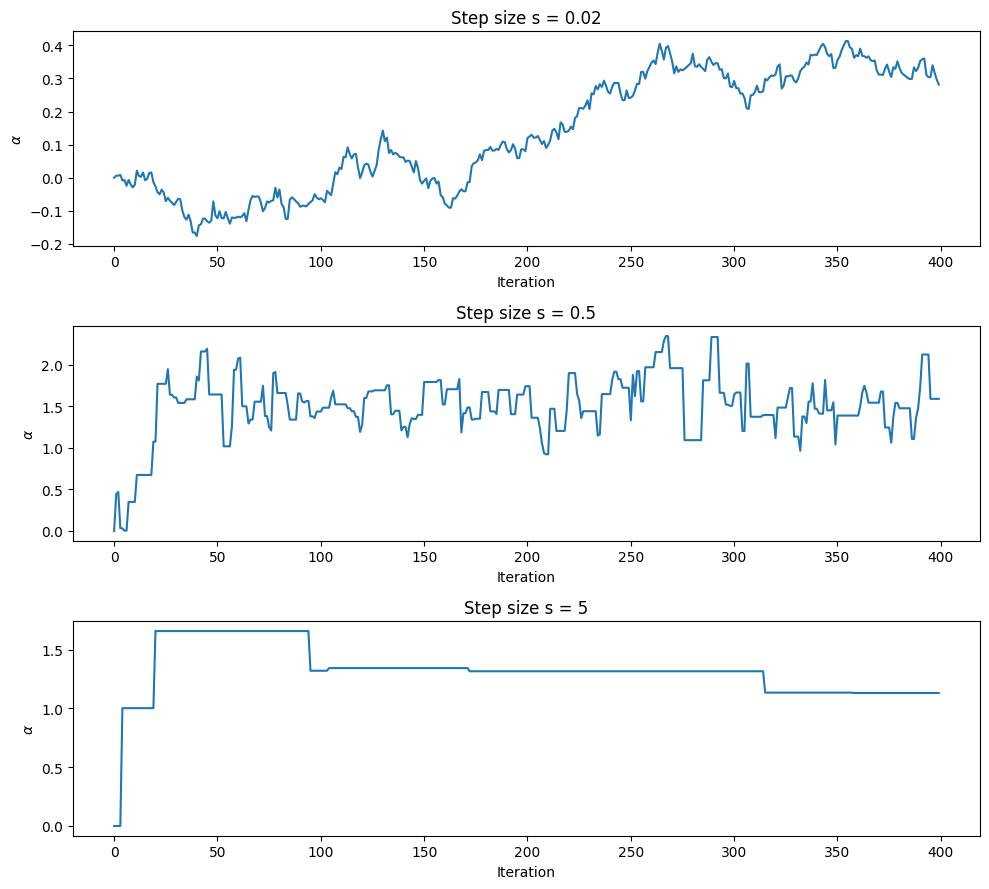

In [ ]:

fig, axes = plt.subplots(3, 1, figsize=(10, 9))

for ax, s in zip(axes, step_sizes):
    alpha_samples = chains[s][:400, 0]

    ax.plot(alpha_samples)
    ax.set_title(f"Step size s = {s}")
    ax.set_xlabel("Iteration")
    ax.set_ylabel(r"$\alpha$")

plt.tight_layout()
plt.show()


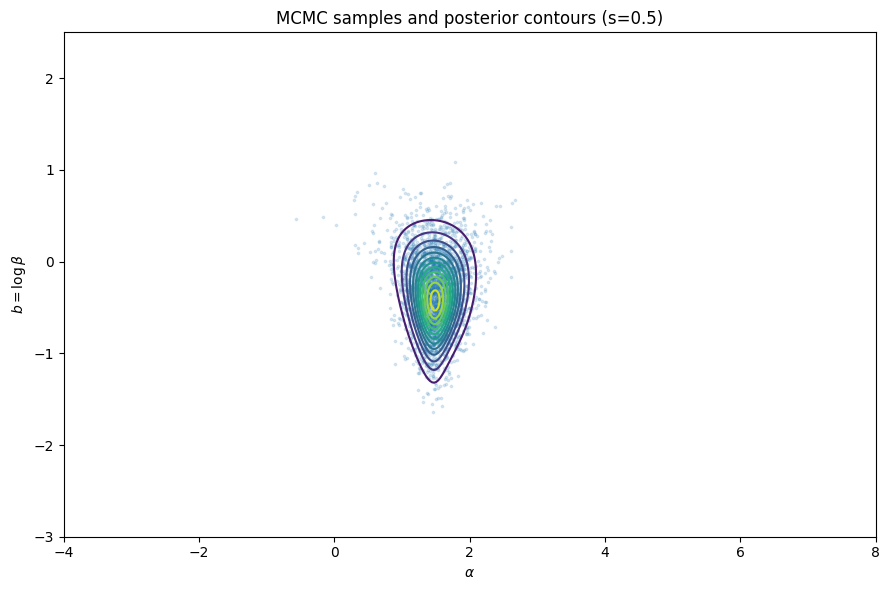

In [ ]:

best_s = results_df.loc[
    results_df["IAT alpha"].idxmin(), "s"
]

chain = chains[best_s][5001:]

alpha_chain = chain[:, 0]
beta_chain = np.exp(chain[:, 1])

alpha_grid = np.linspace(-4, 8, 400)
b_grid = np.linspace(-3, 2.5, 350)

AA, BB = np.meshgrid(alpha_grid, b_grid)

log_density = (
    n*BB -
    np.sum(
        np.log(
            np.exp(2*BB)[..., None]
            + (x-AA[..., None])**2
        ),
        axis=-1
    )
)

density = np.exp(log_density - np.max(log_density))

plt.figure(figsize=(9, 6))
plt.contour(AA, BB, density, levels=12)

plt.scatter(
    alpha_chain[::15],
    chain[::15, 1],
    s=3,
    alpha=0.15
)

plt.xlabel(r"$\alpha$")
plt.ylabel(r"$b=\log\beta$")
plt.title(f"MCMC samples and posterior contours (s={best_s})")
plt.tight_layout()
plt.show()


In [ ]:

weights = density / density.sum()

def weighted_quantile(values, weights, probs):
    values = np.asarray(values).ravel()
    weights = np.asarray(weights).ravel()

    order = np.argsort(values)
    values = values[order]
    weights = weights[order]

    cumulative = np.cumsum(weights)
    cumulative /= cumulative[-1]

    return np.interp(probs, cumulative, values)

mcmc_alpha = [
    np.mean(alpha_chain),
    *np.quantile(alpha_chain, [0.05, 0.95])
]

mcmc_beta = [
    np.mean(beta_chain),
    *np.quantile(beta_chain, [0.05, 0.95])
]

grid_alpha = [
    np.sum(weights*AA),
    *weighted_quantile(AA, weights, [0.05, 0.95])
]

grid_beta = [
    np.sum(weights*np.exp(BB)),
    *weighted_quantile(np.exp(BB), weights, [0.05, 0.95])
]

summary = pd.DataFrame({
    "Parameter": ["alpha", "beta"],
    "MCMC mean": [mcmc_alpha[0], mcmc_beta[0]],
    "MCMC 5%": [mcmc_alpha[1], mcmc_beta[1]],
    "MCMC 95%": [mcmc_alpha[2], mcmc_beta[2]],
    "Grid mean": [grid_alpha[0], grid_beta[0]],
    "Grid 5%": [grid_alpha[1], grid_beta[1]],
    "Grid 95%": [grid_alpha[2], grid_beta[2]]
})

print(summary.to_string(index=False))

print("\nSample mean of x:", np.mean(x))
print("Sample median of x:", np.median(x))


Parameter  MCMC mean  MCMC 5%  MCMC 95%  Grid mean  Grid 5%  Grid 95%
    alpha   1.484644 1.026553  1.937055   1.482719 1.022556  1.924812
     beta   0.784337 0.380545  1.403468   0.775505 0.374259  1.384328

Sample mean of x: 1.6713333333333333
Sample median of x: 1.5


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

alpha = 1.5
beta = 0.8
R = 2000

sample_sizes = [10, 100, 1000]

def scatter(estimates):
    q25, q75 = np.quantile(estimates, [0.25, 0.75])
    return (q75 - q25) / 1.349

results = []
estimates = {}

for n in sample_sizes:

    U = rng.random((R, n))

    X = alpha + beta*np.tan(np.pi*(U - 0.5))

    sample_means = np.mean(X, axis=1)
    sample_medians = np.median(X, axis=1)

    estimates[n] = (sample_means, sample_medians)

    results.append({
        "n": n,
        "Mean scatter": scatter(sample_means),
        "Median scatter": scatter(sample_medians)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


   n  Mean scatter  Median scatter
  10      1.164659        0.389101
 100      1.211418        0.126877
1000      1.165896        0.038995


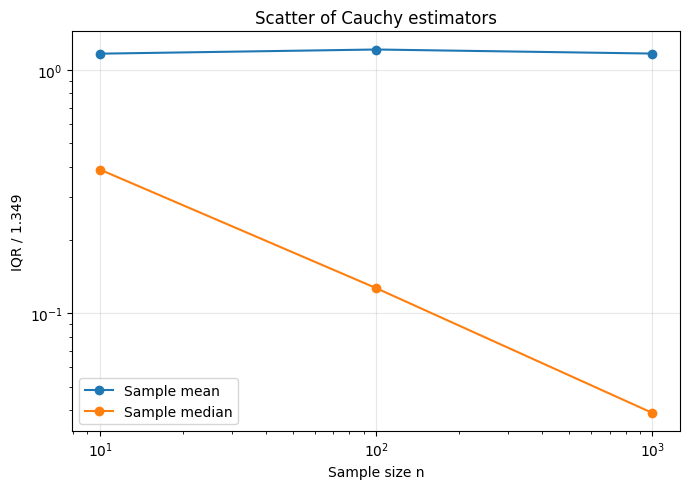

In [ ]:

plt.figure(figsize=(7, 5))

plt.loglog(
    results_df["n"],
    results_df["Mean scatter"],
    "o-",
    label="Sample mean"
)

plt.loglog(
    results_df["n"],
    results_df["Median scatter"],
    "o-",
    label="Sample median"
)

plt.xlabel("Sample size n")
plt.ylabel("IQR / 1.349")
plt.title("Scatter of Cauchy estimators")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Expected time: 2.1073764063261615
Probabilities of finishing last:
Student 1: 0.026786
Student 2: 0.069532
Student 3: 0.122988
Student 4: 0.181252
Student 5: 0.240983
Student 6: 0.358459

Inclusion-exclusion E[M]: 2.107376406326162
Difference: 4.440892098500626e-16

Simulated E[M]: 2.103993593354791
Student 1 last: exact=0.02679, simulation=0.02699
Student 2 last: exact=0.06953, simulation=0.06959
Student 3 last: exact=0.12299, simulation=0.12298
Student 4 last: exact=0.18125, simulation=0.18121
Student 5 last: exact=0.24098, simulation=0.24071
Student 6 last: exact=0.35846, simulation=0.35851


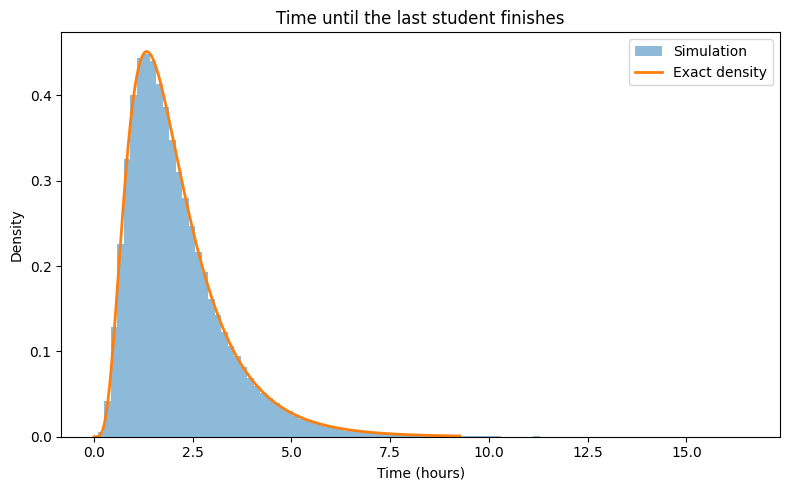


First finishing time conditional on identity:
Theoretical mean: 0.10582010582010583
Student 1: mean first time = 0.10578, count = 63647
Student 2: mean first time = 0.10708, count = 42546
Student 3: mean first time = 0.10537, count = 31369
Student 4: mean first time = 0.10617, count = 25343
Student 5: mean first time = 0.10568, count = 21096
Student 6: mean first time = 0.10557, count = 15999


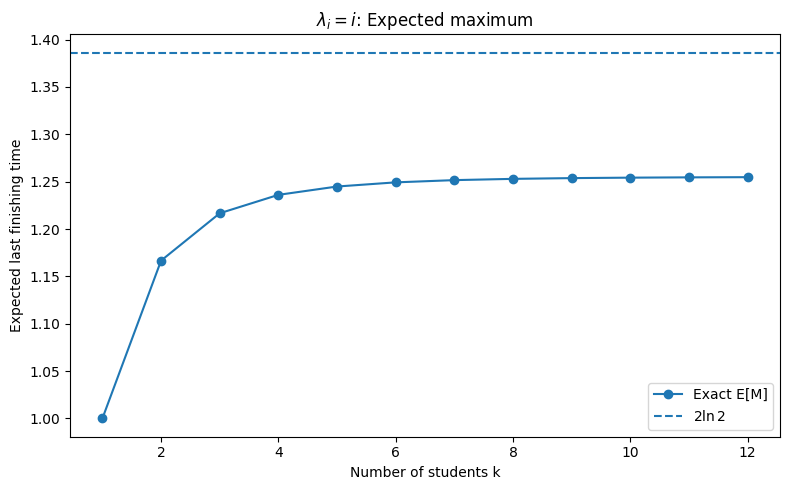


Expected maximum by k:
k= 1, E[M]=1.000000
k= 2, E[M]=1.166667
k= 3, E[M]=1.216667
k= 4, E[M]=1.236111
k= 5, E[M]=1.244902
k= 6, E[M]=1.249295
k= 7, E[M]=1.251653
k= 8, E[M]=1.252989
k= 9, E[M]=1.253780
k=10, E[M]=1.254265
k=11, E[M]=1.254571
k=12, E[M]=1.254769


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from functools import lru_cache

rates = np.array([3, 2, 1.5, 1.2, 1, 0.75])
n = len(rates)

@lru_cache(None)
def group_results(S):
    S = tuple(S)

    if len(S) == 0:
        return 0.0, np.zeros(n)

    total_rate = sum(rates[i] for i in S)

    expected = 1 / total_rate

    last = np.zeros(n)

    if len(S) == 1:
        last[S[0]] = 1.0
        return expected, last

    for i in S:
        remaining = tuple(j for j in S if j != i)
        next_time, next_last = group_results(remaining)

        prob = rates[i] / total_rate

        expected += prob * next_time
        last += prob * next_last

    return expected, last


E_exact, last_exact = group_results(tuple(range(n)))

print("Expected time:", E_exact)
print("Probabilities of finishing last:")

for i in range(n):
    print(f"Student {i+1}: {last_exact[i]:.6f}")

E_alternating = 0

for size in range(1, n+1):
    for group in combinations(range(n), size):
        rate_sum = sum(rates[i] for i in group)
        E_alternating += (-1)**(size+1) / rate_sum

print("\nInclusion-exclusion E[M]:", E_alternating)
print("Difference:", abs(E_exact - E_alternating))


rng = np.random.default_rng(42)
R = 200_000

X = rng.exponential(scale=1/rates, size=(R, n))

M = X.max(axis=1)

first = X.argmin(axis=1)
last = X.argmax(axis=1)
first_times = X.min(axis=1)

print("\nSimulated E[M]:", M.mean())

for i in range(n):
    print(
        f"Student {i+1} last: "
        f"exact={last_exact[i]:.5f}, "
        f"simulation={np.mean(last == i):.5f}"
    )

t = np.linspace(0, np.quantile(M, 0.999), 500)

density = np.zeros_like(t)

for i in range(n):
    term = rates[i] * np.exp(-rates[i]*t)

    for j in range(n):
        if j != i:
            term *= 1 - np.exp(-rates[j]*t)

    density += term

plt.figure(figsize=(8, 5))
plt.hist(M, bins=100, density=True,
         alpha=0.5, label="Simulation")
plt.plot(t, density, linewidth=2,
         label="Exact density")

plt.xlabel("Time (hours)")
plt.ylabel("Density")
plt.title("Time until the last student finishes")
plt.legend()
plt.tight_layout()
plt.show()

print("\nFirst finishing time conditional on identity:")
print("Theoretical mean:", 1/rates.sum())

for i in range(n):
    conditional = first_times[first == i]
    print(
        f"Student {i+1}: "
        f"mean first time = {conditional.mean():.5f}, "
        f"count = {len(conditional)}"
    )

def expected_max_inclusion(lambdas):
    total = 0.0
    k = len(lambdas)

    for size in range(1, k+1):
        for group in combinations(range(k), size):
            total += (-1)**(size+1) / sum(lambdas[i] for i in group)

    return total


ks = np.arange(1, 13)

means = [
    expected_max_inclusion(np.arange(1, k+1))
    for k in ks
]

plt.figure(figsize=(8, 5))
plt.plot(ks, means, "o-", label="Exact E[M]")
plt.axhline(2*np.log(2), linestyle="--",
            label=r"$2\ln 2$")

plt.xlabel("Number of students k")
plt.ylabel("Expected last finishing time")
plt.title(r"$\lambda_i=i$: Expected maximum")
plt.legend()
plt.tight_layout()
plt.show()

print("\nExpected maximum by k:")
for k, value in zip(ks, means):
    print(f"k={k:2d}, E[M]={value:.6f}")


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson, gamma, binom

rng = np.random.default_rng(42)

lam = 4
R = 200_000
t_end = 1.0

counts_gaps = np.zeros(R, dtype=int)
first_gaps = np.full(R, np.nan)
first_half = np.zeros(R, dtype=int)
second_half = np.zeros(R, dtype=int)
raster_gaps = []

for r in range(R):
    time = 0.0
    arrivals = []

    while True:
        time += rng.exponential(1 / lam)

        if time > t_end:
            break

        arrivals.append(time)

    counts_gaps[r] = len(arrivals)

    if arrivals:
        first_gaps[r] = arrivals[0]

    first_half[r] = np.sum(np.array(arrivals) <= 0.5)
    second_half[r] = len(arrivals) - first_half[r]

    if r < 10:
        raster_gaps.append(arrivals)

counts_uniform = rng.poisson(lam * t_end, size=R)
raster_uniform = []

for r in range(10):
    times = np.sort(
        rng.uniform(0, t_end, counts_uniform[r])
    )
    raster_uniform.append(times)

print("Exponential gaps:")
print("Mean:", counts_gaps.mean())
print("Variance:", counts_gaps.var())

print("\nPoisson + uniform:")
print("Mean:", counts_uniform.mean())
print("Variance:", counts_uniform.var())

print("\nTheory: mean = 4, variance = 4")


Exponential gaps:
Mean: 3.99815
Variance: 4.0071965775

Poisson + uniform:
Mean: 3.995355
Variance: 4.001583423975001

Theory: mean = 4, variance = 4


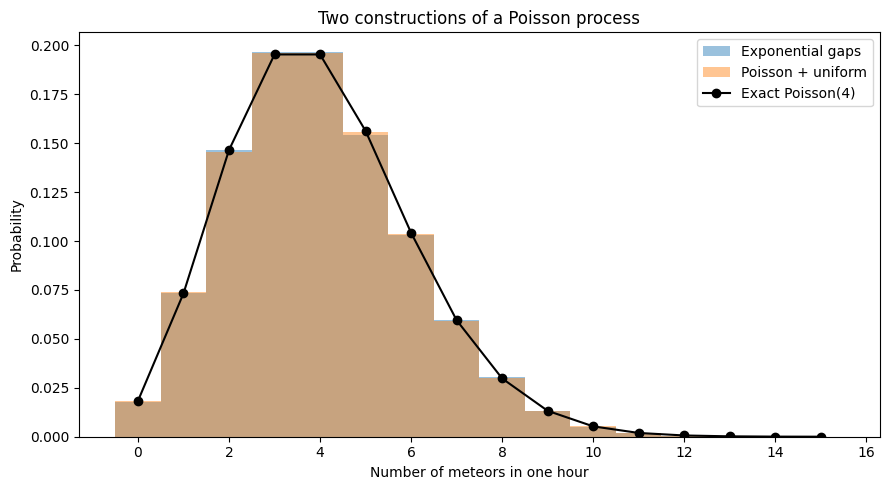

In [ ]:

k = np.arange(0, 16)

plt.figure(figsize=(9, 5))

plt.hist(
    counts_gaps,
    bins=np.arange(-0.5, 16.5),
    density=True,
    alpha=0.45,
    label="Exponential gaps"
)

plt.hist(
    counts_uniform,
    bins=np.arange(-0.5, 16.5),
    density=True,
    alpha=0.45,
    label="Poisson + uniform"
)

plt.plot(
    k, poisson.pmf(k, lam),
    "ko-", label="Exact Poisson(4)"
)

plt.xlabel("Number of meteors in one hour")
plt.ylabel("Probability")
plt.title("Two constructions of a Poisson process")
plt.legend()
plt.tight_layout()
plt.show()


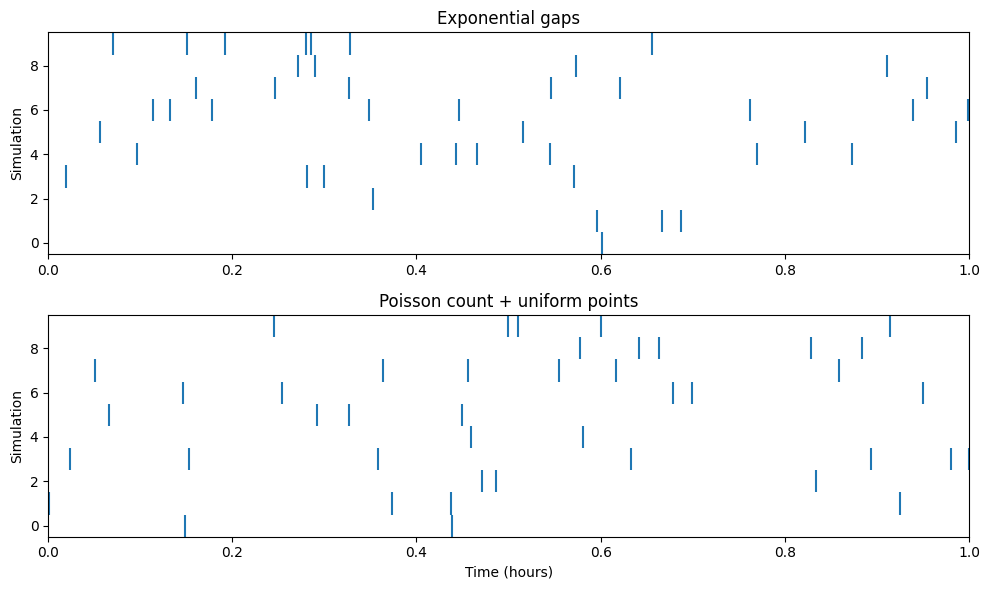

In [ ]:

fig, axes = plt.subplots(2, 1, figsize=(10, 6))

axes[0].eventplot(raster_gaps)
axes[0].set_title("Exponential gaps")
axes[0].set_ylabel("Simulation")

axes[1].eventplot(raster_uniform)
axes[1].set_title("Poisson count + uniform points")
axes[1].set_ylabel("Simulation")
axes[1].set_xlabel("Time (hours)")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.5, 9.5)

plt.tight_layout()
plt.show()


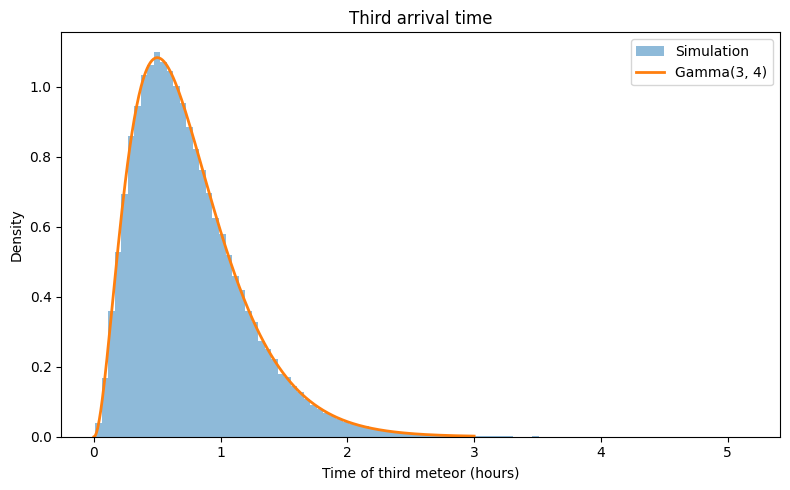

In [ ]:

T3 = rng.exponential(
    scale=1/lam,
    size=(R, 3)
).sum(axis=1)

t = np.linspace(0, 3, 500)

plt.figure(figsize=(8, 5))
plt.hist(
    T3,
    bins=100,
    density=True,
    alpha=0.5,
    label="Simulation"
)

plt.plot(
    t,
    gamma.pdf(t, a=3, scale=1/lam),
    linewidth=2,
    label="Gamma(3, 4)"
)

plt.xlabel("Time of third meteor (hours)")
plt.ylabel("Density")
plt.title("Third arrival time")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

# Restrict to hours with exactly 3 meteors
mask = counts_gaps == 3

prob_zero = np.mean(first_half[mask] == 0)
mean_first = np.mean(first_gaps[mask])

# Correlation over ALL hours
correlation = np.corrcoef(
    first_half,
    second_half
)[0, 1]

print("P(N(0.5)=0 | N(1)=3)")
print("Simulation:", prob_zero)
print("Theory:", 1/8)

print("\nE[T1 | N(1)=3]")
print("Simulation:", mean_first)
print("Theory:", 1/4, "hours")

print("\nCorrelation of half-hour counts:")
print(correlation)
print("Theory: 0")


P(N(0.5)=0 | N(1)=3)
Simulation: 0.12615267369490665
Theory: 0.125

E[T1 | N(1)=3]
Simulation: 0.24927895401368877
Theory: 0.25 hours

Correlation of half-hour counts:
-0.0020031251300005257
Theory: 0
